# PRML Lab 8 — ICA & Sequential Feature Selection
**Aryan Tiwari (B20AI056)** · CSL2050 Pattern Recognition & Machine Learning · Winter 2022

In [1]:
import io
import json
import os
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.io import wavfile
from IPython.display import Audio, display

warnings.filterwarnings('ignore', message='.*encountered in matmul', category=RuntimeWarning)
SEED = 56
sns.set_theme(style='whitegrid')
os.makedirs('outputs', exist_ok=True)
results = {}

def savefig(name):
    plt.savefig(f'figures/{name}.png', dpi=150, bbox_inches='tight')

# Question 1 — Independent Component Analysis

### 1. Read, visualise and listen

3 signals, 264515 samples each, 44100 Hz → 6.00 s
pairwise correlation of the three files:
 [[ 1.0e+00 -4.1e-03 -3.9e-03]
 [-4.1e-03  1.0e+00  2.0e-04]
 [-3.9e-03  2.0e-04  1.0e+00]]
signal_1


signal_2


signal_3


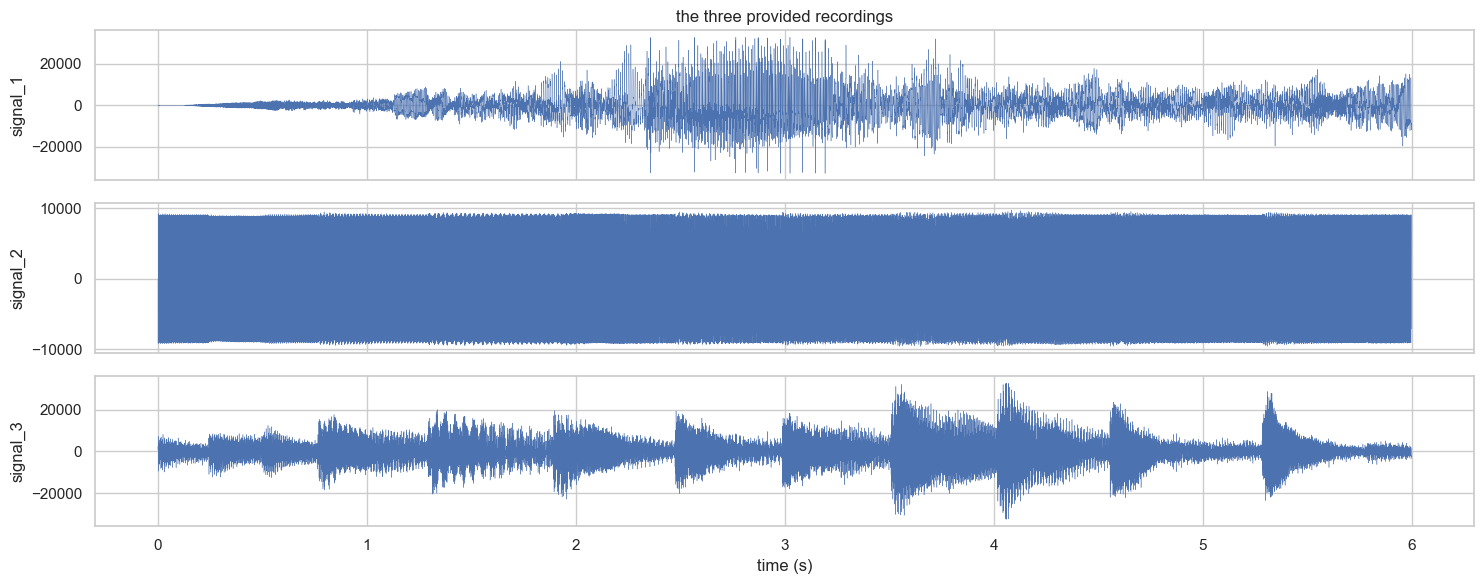

In [2]:
NAMES = ['signal_1', 'signal_2', 'signal_3']
rates, sources = zip(*[wavfile.read(f'data/Q1/{n}.wav') for n in NAMES])
SR = rates[0]
S = np.array(sources, dtype=float)
print(f'{S.shape[0]} signals, {S.shape[1]} samples each, {SR} Hz → {S.shape[1] / SR:.2f} s')
print('pairwise correlation of the three files:\n', np.corrcoef(S).round(4))

def listen(x, label):
    # Embed a 22 kHz preview (keeps the notebook small); full-quality files are written to outputs/
    x = x[::2] / (np.abs(x).max() + 1e-12)
    print(label); display(Audio(x, rate=SR // 2))

for n, s in zip(NAMES, S):
    listen(s, n)

t = np.arange(S.shape[1]) / SR
fig, ax = plt.subplots(3, 1, figsize=(15, 6), sharex=True)
for a, n, s in zip(ax, NAMES, S):
    a.plot(t, s, lw=0.3); a.set_ylabel(n)
ax[-1].set_xlabel('time (s)'); ax[0].set_title('the three provided recordings')
plt.tight_layout(); savefig('q1_sources'); plt.show()

The three recordings are **mutually uncorrelated** (|r| < 0.005). They are the clean independent sources (piano, music and noise), not recordings of a mixture. "Merging them to create X" therefore means **mixing** them, as several microphones in one room would record them. That gives a known ground truth, so ICA's output can be checked against the real sources.

### 2. Build the dataset X by mixing the sources

In [3]:
A = np.array([[1.0, 0.5, 0.6],
              [0.6, 1.0, 0.4],
              [0.4, 0.6, 1.0]])                     # mixing matrix: each 'microphone' hears every source
S_std = S / S.std(1, keepdims=True)                 # equal loudness so no source dominates the mix
X = A @ S_std                                       # X: 3 mixtures × n samples
print('condition number of A:', round(np.linalg.cond(A), 2))
print('correlation between mixtures:\n', np.corrcoef(X).round(3))
for i, x in enumerate(X, 1):
    wavfile.write(f'outputs/mixture_{i}.wav', SR, (x / np.abs(x).max() * 32767).astype(np.int16))
    listen(x, f'mixture {i}')

condition number of A: 4.31
correlation between mixtures:
 [[1.    0.856 0.829]
 [0.856 1.    0.815]
 [0.829 0.815 1.   ]]
mixture 1


mixture 2


mixture 3


### 3. ICA from scratch
1. **Centre** each mixture (subtract its mean).
2. **Whiten** with the eigen-decomposition of the covariance, $\tilde X = D^{-1/2}E^\top X$. The whitened mixtures are uncorrelated with unit variance, so the remaining unmixing is a pure rotation.
3. **Fixed-point updates** (FastICA rule, negentropy approximated with $G(u)=\log\cosh u$, $g=\tanh$, $g'=1-\tanh^2$): $w \leftarrow E[\tilde x\, g(w^\top\tilde x)] - E[g'(w^\top\tilde x)]\,w$, then normalise.
4. **Deflation**: each new $w$ is orthogonalised against the components already found (Gram–Schmidt), so the same source is never found twice.
5. **Convergence**, as specified: stop when $|w_{new}\cdot w_{old}| \approx 1$ (the direction no longer changes; tolerance $10^{-8}$), or after **1000 iterations**.

In [4]:
def ica_scratch(X, n_components, max_iter=1000, tol=1e-8, seed=SEED):
    rng = np.random.default_rng(seed)
    Xc = X - X.mean(1, keepdims=True)
    d, E = np.linalg.eigh(np.cov(Xc))
    K = np.diag(1 / np.sqrt(d)) @ E.T                     # whitening matrix
    Z = K @ Xc
    W = np.zeros((n_components, Z.shape[0]))
    log = []
    for p in range(n_components):
        w = rng.normal(size=Z.shape[0]); w /= np.linalg.norm(w)
        for it in range(1, max_iter + 1):
            u = w @ Z
            g, g_prime = np.tanh(u), 1 - np.tanh(u) ** 2
            w_new = (Z * g).mean(1) - g_prime.mean() * w
            w_new -= W[:p].T @ (W[:p] @ w_new)            # deflation: stay orthogonal to found components
            w_new /= np.linalg.norm(w_new)
            converged = abs(abs(w_new @ w) - 1) < tol     # w·w_old ≈ 1  →  direction has stopped changing
            w = w_new
            if converged:
                break
        W[p] = w
        log.append({'component': p + 1, 'iterations': it, 'converged': bool(converged)})
    return W @ Z, W @ K, pd.DataFrame(log)

t0 = time.time()
S_hat, W_unmix, ica_log = ica_scratch(X, 3)
print(f'finished in {time.time() - t0:.2f}s'); print(ica_log.to_string(index=False))

finished in 0.02s
 component  iterations  converged
         1           3       True
         2           5       True
         3           2       True


In [5]:
def match_sources(S_true, S_est):
    C = np.corrcoef(np.vstack([S_true, S_est]))[:len(S_true), len(S_true):]
    order = np.abs(C).argmax(1)                           # ICA cannot recover order, sign or scale
    signs = np.sign(C[np.arange(len(S_true)), order])
    return order, signs, np.abs(C[np.arange(len(S_true)), order]), C

order, signs, corr_scratch, C_scratch = match_sources(S_std, S_hat)
S_scratch = S_hat[order] * signs[:, None]
results['q1_scratch'] = {'iterations': ica_log['iterations'].tolist(), 'abs_corr_with_true': corr_scratch.round(5).tolist(),
                         'mixing_condition_number': float(np.linalg.cond(A))}
print('|correlation| of each recovered component with its true source:', corr_scratch.round(5))
print('full |correlation| matrix (rows = true sources, cols = ICA outputs):\n', np.abs(C_scratch).round(4))

|correlation| of each recovered component with its true source: [0.99995 0.99971 0.99971]
full |correlation| matrix (rows = true sources, cols = ICA outputs):
 [[0.0072 1.     0.0065]
 [0.9997 0.0112 0.0215]
 [0.0216 0.0105 0.9997]]


### 4. Mixtures, real sources and recovered sources

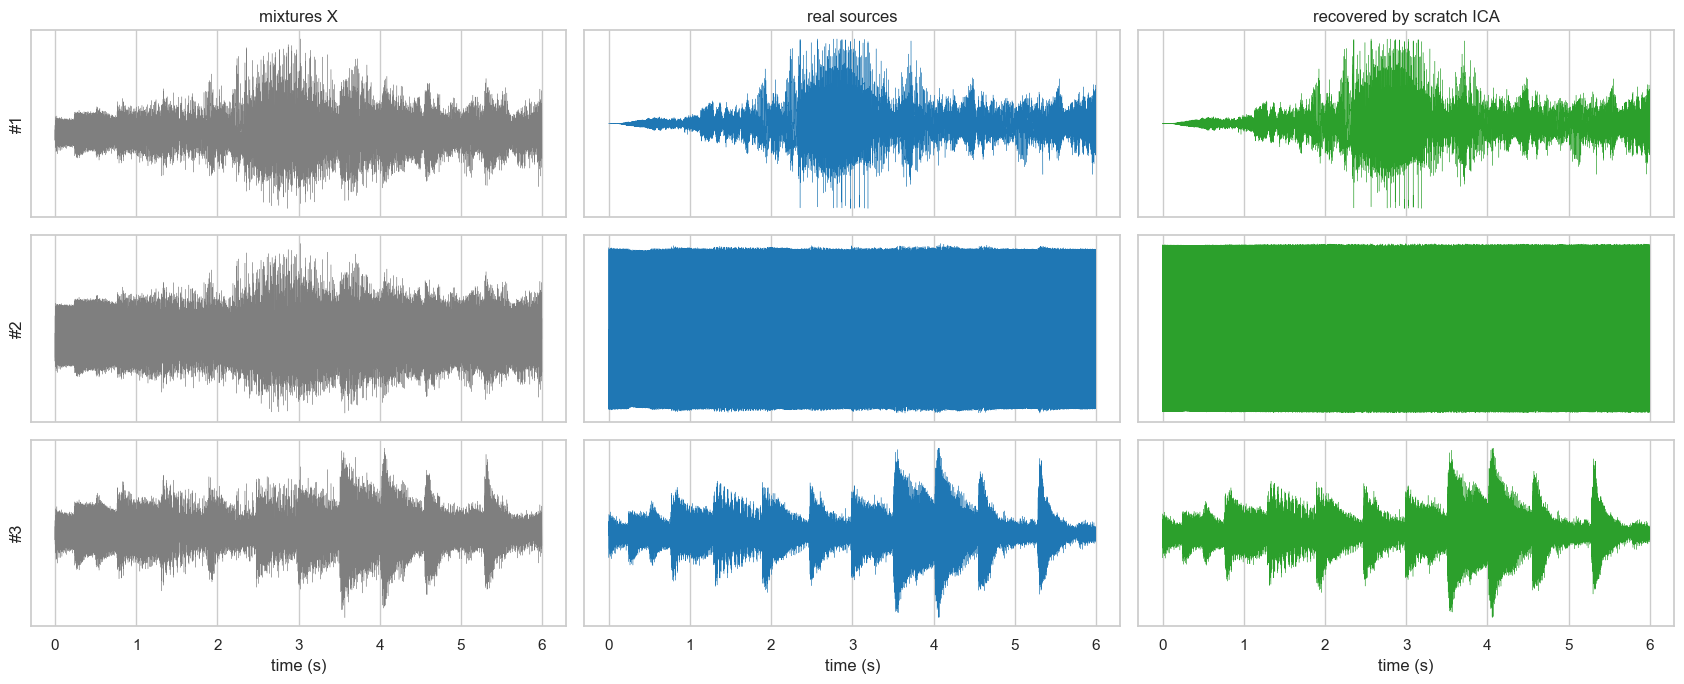

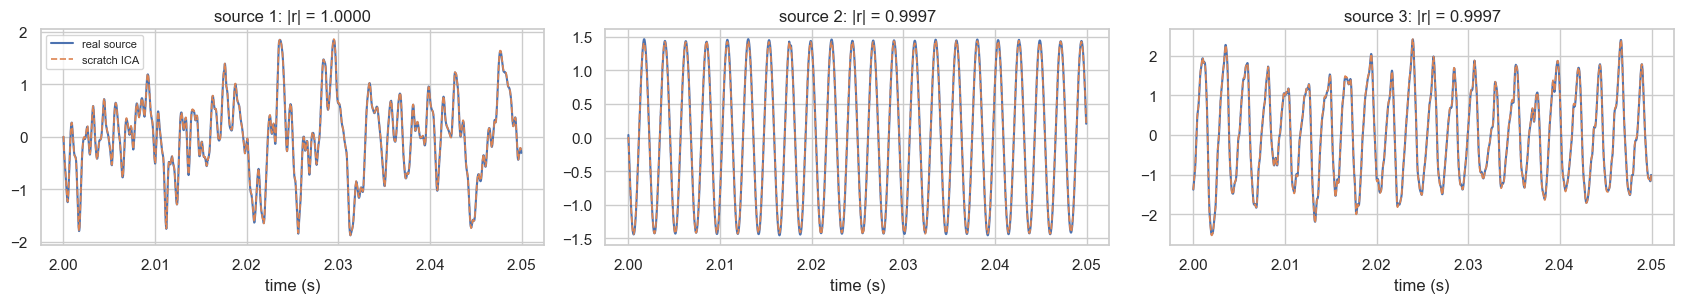

In [6]:
def show_three(rows, titles, name, color_rows=('tab:gray', 'tab:blue', 'tab:green')):
    fig, ax = plt.subplots(3, 3, figsize=(17, 7), sharex=True)
    for c, (block, title) in enumerate(zip(rows, titles)):
        for r in range(3):
            ax[r, c].plot(t, block[r], lw=0.25, color=color_rows[c])
            ax[r, c].set_yticks([])
        ax[0, c].set_title(title)
    for r in range(3):
        ax[r, 0].set_ylabel(f'#{r + 1}')
    for c in range(3):
        ax[2, c].set_xlabel('time (s)')
    plt.tight_layout(); savefig(name); plt.show()

show_three([X, S_std, S_scratch], ['mixtures X', 'real sources', 'recovered by scratch ICA'], 'q1_scratch_ica')
zoom = slice(int(2.0 * SR), int(2.05 * SR))
fig, ax = plt.subplots(1, 3, figsize=(17, 3.2))
for i in range(3):
    ax[i].plot(t[zoom], S_std[i, zoom], lw=1.5, label='real source')
    ax[i].plot(t[zoom], S_scratch[i, zoom] * S_std[i].std() / S_scratch[i].std(), '--', lw=1.2, label='scratch ICA')
    ax[i].set_title(f'source {i + 1}: |r| = {corr_scratch[i]:.4f}'); ax[i].set_xlabel('time (s)')
ax[0].legend(fontsize=8); plt.tight_layout(); savefig('q1_zoom'); plt.show()

### 5–6. FastICA from scikit-learn: separate, visualise, listen

FastICA iterations: 3 | |corr| with true sources: [0.99999 0.99999 0.99996]


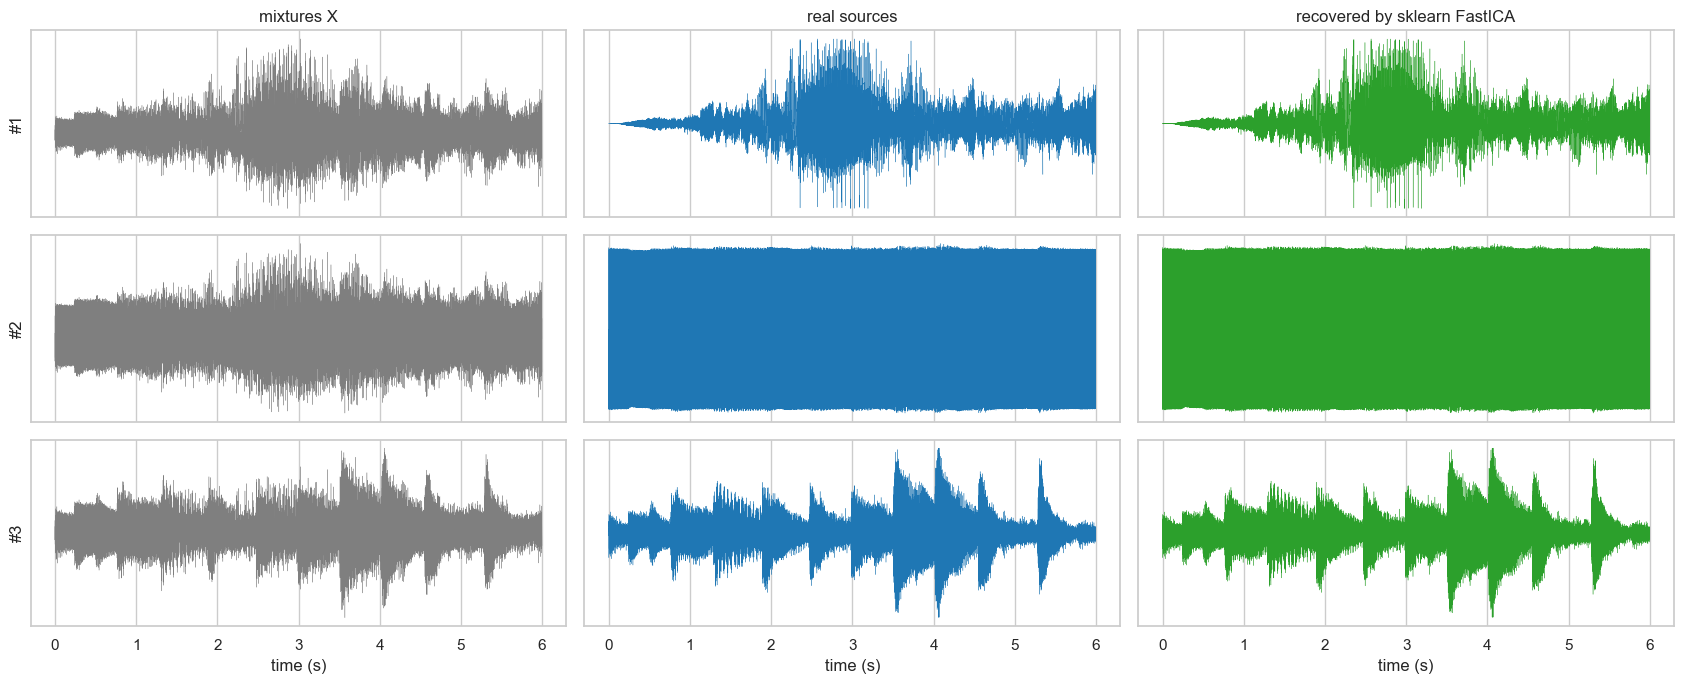

FastICA component 1


FastICA component 2


FastICA component 3


In [7]:
from sklearn.decomposition import FastICA

fast = FastICA(n_components=3, whiten='unit-variance', random_state=SEED, max_iter=1000)
S_fast_raw = fast.fit_transform(X.T).T
order_f, signs_f, corr_fast, _ = match_sources(S_std, S_fast_raw)
S_fast = S_fast_raw[order_f] * signs_f[:, None]
results['q1_fastica'] = {'iterations': int(fast.n_iter_), 'abs_corr_with_true': corr_fast.round(5).tolist()}
print('FastICA iterations:', fast.n_iter_, '| |corr| with true sources:', corr_fast.round(5))
show_three([X, S_std, S_fast], ['mixtures X', 'real sources', 'recovered by sklearn FastICA'], 'q1_fastica')

for i in range(3):
    for tag, est in [('scratch', S_scratch), ('fastica', S_fast)]:
        wavfile.write(f'outputs/{tag}_ica_{i + 1}.wav', SR, (est[i] / np.abs(est[i]).max() * 32767).astype(np.int16))
    listen(S_fast[i], f'FastICA component {i + 1}')

In [8]:
def sir_db(true, est):
    # signal-to-interference ratio after least-squares scaling: how much of the estimate is the right source
    a = (est @ true) / (true @ true)
    err = est - a * true
    return 10 * np.log10(np.sum((a * true) ** 2) / np.sum(err ** 2))

cmp = pd.DataFrame({
    'scratch ICA |r|': corr_scratch, 'FastICA |r|': corr_fast,
    'scratch SIR (dB)': [sir_db(S_std[i], S_scratch[i]) for i in range(3)],
    'FastICA SIR (dB)': [sir_db(S_std[i], S_fast[i]) for i in range(3)],
}, index=[f'source {i + 1}' for i in range(3)])
W_cmp = np.abs(np.corrcoef(np.vstack([S_scratch, S_fast]))[:3, 3:])
results['q1_compare'] = cmp.round(4).to_dict('index')
results['q1_scratch_vs_fast_corr'] = np.diag(W_cmp).round(6).tolist()
print('|corr| between scratch and FastICA outputs:', np.diag(W_cmp).round(6))
cmp.round(4)

|corr| between scratch and FastICA outputs: [0.999976 0.99974  0.999763]


,scratch ICA |r|,FastICA |r|,scratch SIR (dB),FastICA SIR (dB)
source 1,1.0000,1.0,39.0809,42.3998
source 2,0.9997,1.0,32.2921,47.2517
source 3,0.9997,1.0,32.3710,40.7086


# Question 2 — Sequential Feature Selection (Airline Passenger Satisfaction)

### 1. Pre-processing

In [9]:
air = pd.read_csv('data/Q2/train.csv')
print(air.shape); print(air.isna().sum()[air.isna().sum() > 0])
air = air.drop(columns=['Unnamed: 0', 'id'])                         # row index and passenger id carry no signal
print('corr(departure delay, arrival delay) =', round(air['Departure Delay in Minutes'].corr(air['Arrival Delay in Minutes']), 3))

(103904, 25)
Arrival Delay in Minutes    310
dtype: int64
corr(departure delay, arrival delay) = 0.965


- `Unnamed: 0` and `id` are identifiers, so they are dropped.
- `Arrival Delay` is missing for 310 rows. It is almost a copy of `Departure Delay` (r ≈ 0.96), so the missing value is filled with that passenger's departure delay rather than a global median.
- Binary categoricals (`Gender`, `Customer Type`, `Type of Travel`) become 0/1. `Class` is ordinal: Eco < Eco Plus < Business.
- The 14 service ratings are already on a 0–5 scale. A decision tree doesn't need scaling, so features are left in their natural units.
- Label: `satisfied` = 1.

In [10]:
air['Arrival Delay in Minutes'] = air['Arrival Delay in Minutes'].fillna(air['Departure Delay in Minutes'])
air['Gender'] = (air['Gender'] == 'Male').astype(int)
air['Customer Type'] = (air['Customer Type'] == 'Loyal Customer').astype(int)
air['Type of Travel'] = (air['Type of Travel'] == 'Business travel').astype(int)
air['Class'] = air['Class'].map({'Eco': 0, 'Eco Plus': 1, 'Business': 2})
Y_all = (air.pop('satisfaction') == 'satisfied').astype(int).values
X_all = air
FEATURES = X_all.columns.tolist()
print(X_all.shape, '| missing:', X_all.isna().sum().sum(), '| satisfied share:', Y_all.mean().round(3))

# SFS retrains the tree hundreds of times with 4-fold CV; a stratified 20k-row sample keeps every run to seconds
from sklearn.model_selection import train_test_split
X, _, Y, _ = train_test_split(X_all, Y_all, train_size=20000, stratify=Y_all, random_state=SEED)
print('SFS working sample:', X.shape)

(103904, 22) | missing: 0 | satisfied share: 0.433
SFS working sample: (20000, 22)


### 2–3. SFS(forward, not floating, k = 10, accuracy) with a decision tree

In [11]:
from mlxtend.feature_selection import SequentialFeatureSelector as SFS
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(random_state=SEED)
t0 = time.time()
sfs = SFS(tree, k_features=10, forward=True, floating=False, scoring='accuracy', cv=4, n_jobs=-1).fit(X, Y)
best10 = list(sfs.k_feature_names_)
results['q2_sfs10'] = {'cv_accuracy': float(sfs.k_score_), 'features': best10, 'seconds': round(time.time() - t0, 1)}
print(f'CV accuracy with the 10 selected features: {sfs.k_score_:.4f}  ({time.time() - t0:.1f}s)')
for i, f in enumerate(best10, 1):
    print(f'  {i:2d}. {f}')

CV accuracy with the 10 selected features: 0.9384  (3.5s)
   1. Gender
   2. Customer Type
   3. Type of Travel
   4. Class
   5. Inflight wifi service
   6. Ease of Online booking
   7. Gate location
   8. Online boarding
   9. Baggage handling
  10. Inflight service


### 4–6. SFS, SBS, SFFS and SBFS (cv = 4)

In [12]:
CONFIGS = {'SFS': (True, False), 'SBS': (False, False), 'SFFS': (True, True), 'SBFS': (False, True)}
fitted, cfg_rows = {}, []
for name, (fwd, flt) in CONFIGS.items():
    t0 = time.time()
    m = SFS(DecisionTreeClassifier(random_state=SEED), k_features=10, forward=fwd, floating=flt,
            scoring='accuracy', cv=4, n_jobs=-1).fit(X, Y)
    fitted[name] = m
    cfg_rows.append({'config': name, 'forward': fwd, 'floating': flt, 'CV accuracy (10 features)': m.k_score_,
                     'fold scores': np.round(m.subsets_[10]['cv_scores'], 4).tolist(), 'seconds': round(time.time() - t0, 1),
                     'features': ', '.join(m.k_feature_names_)})
cfg_df = pd.DataFrame(cfg_rows).set_index('config')
results['q2_configs'] = cfg_df.drop(columns='features').round(4).to_dict('index')
results['q2_config_features'] = {k: list(m.k_feature_names_) for k, m in fitted.items()}
cfg_df.drop(columns='features').round(4)

,forward,floating,CV accuracy (10 features),fold scores,seconds
config,,,,,
SFS,True,False,0.9384,"[0.9396, 0.9406, 0.9352, 0.9382]",2.2
SBS,False,False,0.9387,"[0.9368, 0.9426, 0.9416, 0.9338]",5.6
SFFS,True,True,0.9384,"[0.9396, 0.9406, 0.9352, 0.9382]",3.6
SBFS,False,True,0.9387,"[0.9368, 0.9426, 0.9416, 0.9338]",9.9


In [13]:
for name, m in fitted.items():
    print(f'=== {name}: metric dict as a DataFrame')
    display(pd.DataFrame.from_dict(m.get_metric_dict()).T[['feature_names', 'avg_score', 'std_dev', 'ci_bound']].tail(6))

=== SFS: metric dict as a DataFrame


,feature_names,avg_score,std_dev,ci_bound
5,"(Customer Type, Type of Travel, Inflight wifi ...",0.9244,0.000283,0.000453
6,"(Customer Type, Type of Travel, Inflight wifi ...",0.93555,0.001797,0.00288
7,"(Customer Type, Type of Travel, Inflight wifi ...",0.93985,0.00326,0.005226
8,"(Customer Type, Type of Travel, Class, Infligh...",0.9419,0.003074,0.004928
9,"(Customer Type, Type of Travel, Class, Infligh...",0.94035,0.001596,0.002559
10,"(Gender, Customer Type, Type of Travel, Class,...",0.9384,0.002035,0.003262


=== SBS: metric dict as a DataFrame


,feature_names,avg_score,std_dev,ci_bound
15,"(Gender, Customer Type, Age, Type of Travel, C...",0.93915,0.001403,0.002248
14,"(Gender, Customer Type, Age, Type of Travel, C...",0.93855,0.001052,0.001687
13,"(Customer Type, Age, Type of Travel, Class, In...",0.9382,0.001934,0.0031
12,"(Customer Type, Age, Type of Travel, Class, In...",0.93815,0.002636,0.004225
11,"(Customer Type, Type of Travel, Class, Infligh...",0.93705,0.002286,0.003665
10,"(Customer Type, Type of Travel, Class, Infligh...",0.9387,0.003579,0.005737


=== SFFS: metric dict as a DataFrame


,feature_names,avg_score,std_dev,ci_bound
5,"(Customer Type, Type of Travel, Inflight wifi ...",0.9244,0.000283,0.000453
6,"(Customer Type, Type of Travel, Inflight wifi ...",0.93555,0.001797,0.00288
7,"(Customer Type, Type of Travel, Inflight wifi ...",0.93985,0.00326,0.005226
8,"(Customer Type, Type of Travel, Class, Infligh...",0.9419,0.003074,0.004928
9,"(Customer Type, Type of Travel, Class, Infligh...",0.94035,0.001596,0.002559
10,"(Gender, Customer Type, Type of Travel, Class,...",0.9384,0.002035,0.003262


=== SBFS: metric dict as a DataFrame


,feature_names,avg_score,std_dev,ci_bound
15,"(Gender, Customer Type, Age, Type of Travel, C...",0.9392,0.000927,0.001487
14,"(Gender, Customer Type, Age, Type of Travel, C...",0.93855,0.001052,0.001687
13,"(Customer Type, Age, Type of Travel, Class, In...",0.9382,0.001934,0.0031
12,"(Customer Type, Age, Type of Travel, Class, In...",0.93815,0.002636,0.004225
11,"(Customer Type, Type of Travel, Class, Infligh...",0.9393,0.003822,0.006127
10,"(Customer Type, Type of Travel, Class, Infligh...",0.9387,0.003579,0.005737


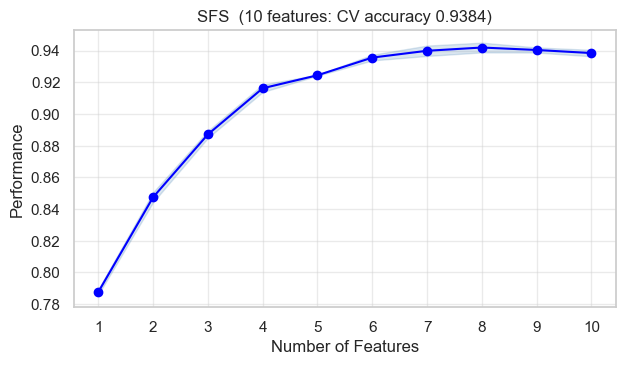

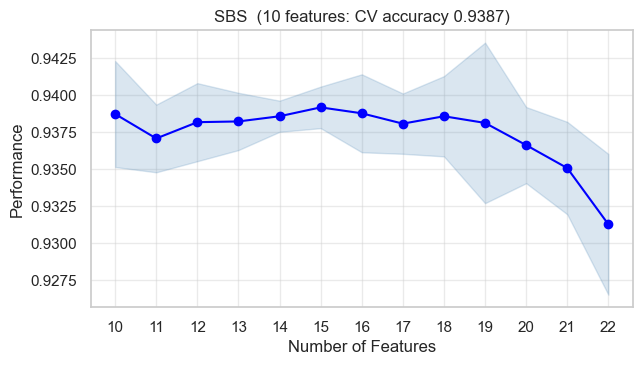

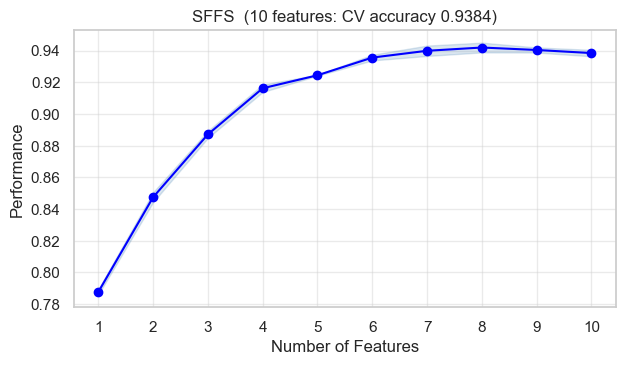

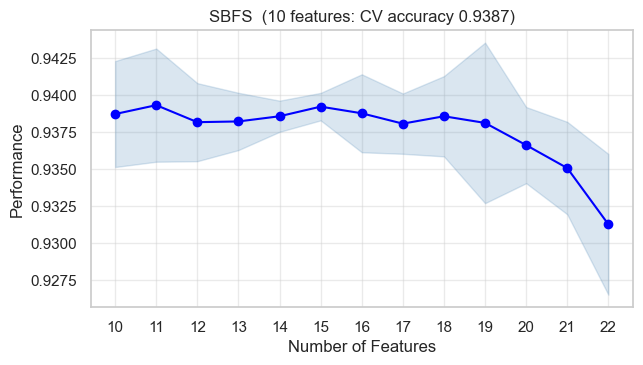

In [14]:
from mlxtend.plotting import plot_sequential_feature_selection as plot_sfs
for name, m in fitted.items():
    fig, ax = plot_sfs(m.get_metric_dict(), kind='std_dev', figsize=(7, 3.6))
    ax.set_title(f'{name}  (10 features: CV accuracy {m.k_score_:.4f})'); ax.grid(alpha=0.4)
    savefig(f'q2_plot_{name}'); plt.show()

In [15]:
common = set.intersection(*[set(m.k_feature_names_) for m in fitted.values()])
results['q2_common_features'] = sorted(common)
presence = pd.DataFrame({name: [f in m.k_feature_names_ for f in FEATURES] for name, m in fitted.items()}, index=FEATURES)
presence = presence[presence.any(axis=1)].astype(int)
print(f'{len(common)} features chosen by all four methods:', sorted(common))
presence.sort_values(list(CONFIGS), ascending=False)

7 features chosen by all four methods: ['Baggage handling', 'Class', 'Customer Type', 'Gate location', 'Inflight service', 'Inflight wifi service', 'Type of Travel']


,SFS,SBS,SFFS,SBFS
Customer Type,1,1,1,1
Type of Travel,1,1,1,1
Class,1,1,1,1
Inflight wifi service,1,1,1,1
Gate location,1,1,1,1
Baggage handling,1,1,1,1
Inflight service,1,1,1,1
Gender,1,0,1,0
Ease of Online booking,1,0,1,0
Online boarding,1,0,1,0


### 7. Changing the number of selected features

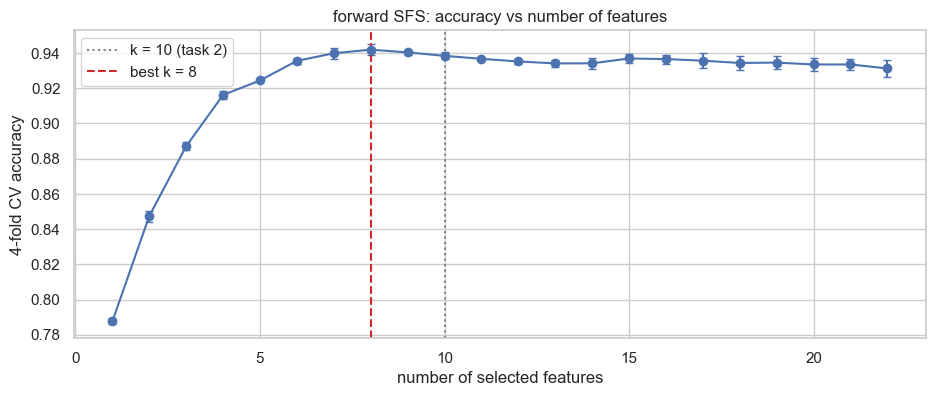

,CV accuracy,std,added feature
1,0.7876,0.001639,Online boarding
2,0.8474,0.003109,Type of Travel
3,0.8871,0.002234,Inflight wifi service
4,0.9162,0.002345,Gate location
5,0.9244,0.000283,Customer Type
6,0.9356,0.001797,Baggage handling
7,0.9398,0.00326,Inflight service
8,0.9419,0.003074,Class
9,0.9404,0.001596,Ease of Online booking
10,0.9384,0.002035,Gender


In [16]:
full = SFS(DecisionTreeClassifier(random_state=SEED), k_features=len(FEATURES), forward=True, floating=False,
           scoring='accuracy', cv=4, n_jobs=-1).fit(X, Y)
curve = pd.DataFrame({k: {'CV accuracy': v['avg_score'], 'std': v['cv_scores'].std(), 'added feature': ''} for k, v in full.subsets_.items()}).T
prev = set()
for k in sorted(full.subsets_):
    cur = set(full.subsets_[k]['feature_names']); curve.loc[k, 'added feature'] = ', '.join(cur - prev); prev = cur
curve['CV accuracy'] = curve['CV accuracy'].astype(float)
best_k = int(curve['CV accuracy'].idxmax())
results['q2_k_curve'] = curve[['CV accuracy', 'added feature']].round(4).to_dict('index')
results['q2_best_k'] = {'k': best_k, 'acc': float(curve.loc[best_k, 'CV accuracy']), 'acc_all': float(curve.loc[len(FEATURES), 'CV accuracy'])}
fig, ax = plt.subplots(figsize=(11, 4))
ax.errorbar(curve.index.astype(int), curve['CV accuracy'], yerr=curve['std'].astype(float), fmt='o-', capsize=3)
ax.axvline(10, ls=':', c='grey', label='k = 10 (task 2)'); ax.axvline(best_k, ls='--', c='tab:red', label=f'best k = {best_k}')
ax.set_xlabel('number of selected features'); ax.set_ylabel('4-fold CV accuracy'); ax.legend(); ax.set_title('forward SFS: accuracy vs number of features')
savefig('q2_k_curve'); plt.show()
curve.round(4)

### Bonus — forward SFS from scratch
At each step, every remaining feature is tried, the one whose addition gives the highest mean 4-fold CV accuracy is added, and the loop stops at k features. The selection order should match mlxtend's exactly when both use the same folds and the same tree.

In [17]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

def sfs_scratch(estimator, X, y, k, cv=4):
    selected, remaining, trace = [], list(X.columns), []
    folds = StratifiedKFold(cv, shuffle=False)                # mlxtend uses unshuffled stratified folds for classifiers
    while len(selected) < k:
        scores = {f: cross_val_score(estimator, X[selected + [f]], y, cv=folds, scoring='accuracy', n_jobs=-1).mean() for f in remaining}
        best = max(scores, key=scores.get)
        selected.append(best); remaining.remove(best)
        trace.append({'step': len(selected), 'added': best, 'CV accuracy': scores[best]})
    return selected, pd.DataFrame(trace).set_index('step')

t0 = time.time()
mine, trace = sfs_scratch(DecisionTreeClassifier(random_state=SEED), X, Y, 10)
same = mine == [full.subsets_[i]['feature_names'] for i in range(1, 11)] or set(mine) == set(fitted['SFS'].k_feature_names_)
results['q2_bonus'] = {'features': mine, 'cv_accuracy': float(trace['CV accuracy'].iloc[-1]),
                       'same_set_as_mlxtend': set(mine) == set(fitted['SFS'].k_feature_names_), 'seconds': round(time.time() - t0, 1)}
print(f'scratch SFS selects the same 10 features as mlxtend: {set(mine) == set(fitted["SFS"].k_feature_names_)}  ({time.time() - t0:.1f}s)')
trace.round(4)

scratch SFS selects the same 10 features as mlxtend: True  (4.7s)


,added,CV accuracy
step,,
1,Online boarding,0.7876
2,Type of Travel,0.8474
3,Inflight wifi service,0.8871
4,Gate location,0.9162
5,Customer Type,0.9244
6,Baggage handling,0.9356
7,Inflight service,0.9398
8,Class,0.9419
9,Ease of Online booking,0.9407


In [18]:
with open('results.json', 'w') as f:
    json.dump(results, f, indent=2, default=float)